# Which patients should insurance companies prioritize for further care management assessment? — Exploratory Data Analysis

**Data:** MEPS HC-256, 2024 Full Year Consolidated Data File (AHRQ)

**Stakeholder:** Health insurance manager deciding **which members to prioritize for care-management assessment**


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Chart style: light grid, thin marks, one highlight color
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b8b7b0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "font.size": 10,
})

## 1. Load the data

The Excel file is ~90 MB and takes ~5 minutes to read, so the first run saves a fast `.pkl` copy next to this notebook and later runs load that instead.
Update `DATA_PATH` if the file lives somewhere else.

In [2]:
DATA_PATH = Path.home() / "Downloads" / "h256.xlsx"
CACHE_PATH = Path("h256.pkl")

if CACHE_PATH.exists():
    raw = pd.read_pickle(CACHE_PATH)
else:
    raw = pd.read_excel(DATA_PATH)      # slow (~5 min)
    raw.to_pickle(CACHE_PATH)

print(f"{raw.shape[0]:,} people x {raw.shape[1]:,} variables")

19,140 people x 1,615 variables


## 2. Data Cleaning

The full file has 1,600+ columns. We keep the ones tied to our research questions.

**MEPS coding notes**
- Negative values are missing codes: `-1` inapplicable, `-7` refused, `-8` don't know, `-15` cannot be computed → set to `NaN`.
- Yes/No questions use `1 = Yes, 2 = No` → recoded to `1/0`.
- Most chronic-condition questions are **asked only of adults**; for children they are `-1` (inapplicable), which we treat as "not diagnosed".
- People with `PERWT24F == 0` are out of scope for the 2024 population (e.g., not in the population all year) and are dropped.

In [3]:
keep = {
    # id / design / outcome
    "DUPERSID": "id", "PERWT24F": "weight", "VARSTR": "varstr", "VARPSU": "varpsu",
    "TOTEXP24": "total_exp",
    # expenditure components
    "OBVEXP24": "exp_office", "OPTEXP24": "exp_outpatient", "ERTEXP24": "exp_er",
    "IPTEXP24": "exp_inpatient", "RXEXP24": "exp_rx", "DVTEXP24": "exp_dental",
    "HHAEXP24": "exp_homehealth_agency", "HHNEXP24": "exp_homehealth_other",
    "VISEXP24": "exp_vision", "OTHEXP24": "exp_other",
    # utilization (descriptive only - NOT model features, see Section 7)
    "OBTOTV24": "n_office_visits", "ERTOT24": "n_er_visits", "IPDIS24": "n_inpatient_stays",
    "RXTOT24": "n_rx_fills",
    # demographics / socioeconomic
    "AGE24X": "age", "SEX": "sex", "RACETHX": "race_eth", "REGION24": "region",
    "POVCAT24": "income_cat", "FAMINC24": "family_income", "HIDEG": "education",
    "MARRY24X": "marital",
    # insurance
    "INSCOV24": "insurance",
    # health status
    "RTHLTH53": "self_health", "MNHLTH53": "mental_health", "ANYLMI24": "any_limitation",
    "ADBMI42": "bmi", "OFTSMK53": "smoking",
    # chronic conditions (ever diagnosed)
    "DIABDX_M18": "diabetes", "HIBPDX": "hypertension", "CHDDX": "coronary_hd",
    "ANGIDX": "angina", "MIDX": "heart_attack", "OHRTDX": "other_heart",
    "STRKDX": "stroke", "EMPHDX": "emphysema", "CHOLDX": "high_cholesterol",
    "CANCERDX": "cancer", "ARTHDX": "arthritis", "ASTHDX": "asthma",
}
missing_cols = [c for c in keep if c not in raw.columns]
print("Missing columns:", missing_cols)

df = raw[[c for c in keep if c in raw.columns]].rename(columns=keep).copy()
print("Out-of-scope (weight = 0):", (df.weight == 0).sum())
df = df[df.weight > 0].reset_index(drop=True)
print(f"Analytic sample: {len(df):,} people, representing {df.weight.sum()/1e6:,.1f}M Americans")

Missing columns: []
Out-of-scope (weight = 0): 457
Analytic sample: 18,683 people, representing 339.8M Americans


In [4]:
# --- Recode missing values ---
skip_neg = [c for c in df.columns if c.startswith(("exp_", "n_")) or c in ("total_exp", "family_income", "id", "weight")]
for c in df.columns.difference(skip_neg):
    df.loc[df[c] < 0, c] = np.nan     # family_income can be legitimately negative, so it is skipped

conditions = ["diabetes", "hypertension", "coronary_hd", "angina", "heart_attack", "other_heart",
              "stroke", "emphysema", "high_cholesterol", "cancer", "arthritis", "asthma"]
for c in conditions + ["any_limitation"]:
    df[c] = df[c].map({1: 1, 2: 0})
# Children were not asked most condition questions -> treat as not diagnosed
child = df.age < 18
df.loc[child, conditions] = df.loc[child, conditions].fillna(0)

df["n_conditions"] = df[conditions].sum(axis=1, min_count=1)

# --- Readable labels ---
labels = {
    "sex": {1: "Male", 2: "Female"},
    "race_eth": {1: "Hispanic", 2: "NH White", 3: "NH Black", 4: "NH Asian", 5: "NH Other/Multiple"},
    "region": {1: "Northeast", 2: "Midwest", 3: "South", 4: "West"},
    "income_cat": {1: "Poor (<100% FPL)", 2: "Near poor (100-125%)", 3: "Low (125-200%)",
                   4: "Middle (200-400%)", 5: "High (400%+)"},
    "insurance": {1: "Any private", 2: "Public only", 3: "Uninsured"},
    "self_health": {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"},
    "mental_health": {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"},
    "smoking": {1: "Every day", 2: "Some days", 3: "Not at all"},
}
for col, m in labels.items():
    df[col + "_lbl"] = pd.Categorical(df[col].map(m), categories=list(m.values()), ordered=True)

df["age_group"] = pd.cut(df.age, [-1, 17, 34, 49, 64, 74, 120],
                         labels=["0-17", "18-34", "35-49", "50-64", "65-74", "75+"])
df["bmi_cat"] = pd.cut(df.bmi, [0, 18.5, 25, 30, 35, 100],
                       labels=["Underweight", "Normal", "Overweight", "Obese I", "Obese II+"], right=False)
df["n_conditions_grp"] = pd.cut(df.n_conditions, [-1, 0, 1, 2, 3, 100], labels=["0", "1", "2", "3", "4+"])
df.head()

,id,weight,varstr,varpsu,total_exp,exp_office,exp_outpatient,exp_er,exp_inpatient,exp_rx,exp_dental,exp_homehealth_agency,exp_homehealth_other,exp_vision,exp_other,n_office_visits,n_er_visits,n_inpatient_stays,n_rx_fills,age,sex,race_eth,region,income_cat,family_income,...,smoking,diabetes,hypertension,coronary_hd,angina,heart_attack,other_heart,stroke,emphysema,high_cholesterol,cancer,arthritis,asthma,n_conditions,sex_lbl,race_eth_lbl,region_lbl,income_cat_lbl,insurance_lbl,self_health_lbl,mental_health_lbl,smoking_lbl,age_group,bmi_cat,n_conditions_grp
0,2810003101,"16,532.18","2,062.00",1.00,12912,2347,507,6245,899,198,973,0,0,210,1533,14,1,1,17,67.00,2.00,2.00,4.00,5.00,82732,...,3.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,3.00,Female,NH White,West,High (400%+),Public only,Good,Fair,Not at all,65-74,Underweight,3
1,2810006101,"41,818.01","2,012.00",1.00,875,84,0,0,0,0,662,0,0,129,0,1,0,0,0,47.00,2.00,3.00,3.00,5.00,299000,...,3.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,Female,NH Black,South,High (400%+),Any private,Excellent,Very good,Not at all,35-49,Overweight,1
2,2810006102,"31,330.07","2,012.00",1.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,51.00,1.00,3.00,3.00,5.00,299000,...,3.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Male,NH Black,South,High (400%+),Any private,Very good,Very good,Not at all,50-64,Obese I,0
3,2810006103,"47,067.70","2,012.00",1.00,3665,220,0,0,0,13,3432,0,0,0,0,2,0,0,3,14.00,2.00,3.00,3.00,5.00,299000,...,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Female,NH Black,South,High (400%+),Any private,Excellent,Excellent,NaN,0-17,NaN,0
4,2810006104,"33,240.15","2,012.00",1.00,282,282,0,0,0,0,0,0,0,0,0,1,0,0,0,20.00,1.00,3.00,3.00,5.00,299000,...,3.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,Male,NH Black,South,High (400%+),Any private,Excellent,Very good,Not at all,18-34,Overweight,1


### Data quality check: missingness in the analysis variables

In [5]:
analysis_vars = ["total_exp", "age", "sex", "race_eth", "region", "income_cat", "insurance",
                 "self_health", "mental_health", "any_limitation", "bmi", "smoking", "n_conditions"] + conditions
miss = df[analysis_vars].isna().mean().sort_values(ascending=False).mul(100).round(1)
miss.to_frame("% missing")

,% missing
bmi,42.00
smoking,20.50
any_limitation,1.90
mental_health,1.30
self_health,1.20
age,0.80
region,0.80
high_cholesterol,0.80
hypertension,0.70
angina,0.70


Most variables are nearly complete. BMI and smoking are only collected for adults, so their missingness is largely the children in the sample.

## 3. Exploratory Data Analysis (EDA)
### 3.1  Spending distribution and the high-cost definition

Weighted helpers so every number below is a **US population estimate**, not just a sample statistic.

In [6]:
def wquantile(x, w, q):
    x, w = np.asarray(x, float), np.asarray(w, float)
    idx = np.argsort(x)
    x, w = x[idx], w[idx]
    cw = np.cumsum(w) / w.sum()
    return np.interp(q, cw, x)

def wmean(x, w):
    return np.average(x, weights=w)

y, w = df.total_exp, df.weight
summary = pd.Series({
    "Weighted mean ($)": wmean(y, w),
    "Weighted median ($)": wquantile(y, w, 0.5),
    "75th percentile ($)": wquantile(y, w, 0.75),
    "90th percentile ($)": wquantile(y, w, 0.90),
    "99th percentile ($)": wquantile(y, w, 0.99),
    "Max ($)": y.max(),
    "% with $0 spending": np.average(y == 0, weights=w) * 100,
    "Total US spending ($B)": (y * w).sum() / 1e9,
})
summary.to_frame("2024")

,2024
Weighted mean ($),"8,346.52"
Weighted median ($),"1,700.00"
75th percentile ($),"6,704.10"
90th percentile ($),"19,928.29"
99th percentile ($),"100,314.34"
Max ($),"1,246,195.00"
% with $0 spending,14.52
Total US spending ($B),"2,836.13"


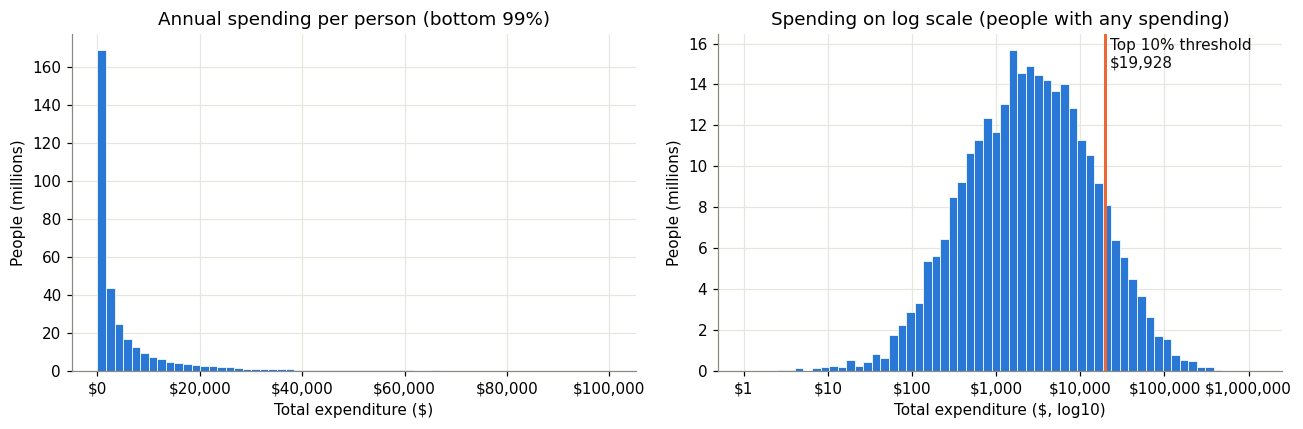

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Raw scale: extreme right skew
p99 = wquantile(y, w, 0.99); m99 = y <= p99
axes[0].hist(y[m99], bins=60, weights=w[m99] / 1e6, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set(title="Annual spending per person (bottom 99%)", xlabel="Total expenditure ($)", ylabel="People (millions)")
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

# Log scale: easier to read (excludes $0 spenders)
pos = y > 0
axes[1].hist(np.log10(y[pos]), bins=60, weights=w[pos] / 1e6, color=BLUE, edgecolor="white", linewidth=0.5)
p90 = wquantile(y, w, 0.90)
axes[1].axvline(np.log10(p90), color=ORANGE, lw=2)
axes[1].text(np.log10(p90) + 0.05, axes[1].get_ylim()[1] * 0.9, f"Top 10% threshold\n${p90:,.0f}", color="#0b0b0b")
axes[1].set(title="Spending on log scale (people with any spending)", xlabel="Total expenditure ($, log10)", ylabel="People (millions)")
axes[1].set_xticks(range(0, 7)); axes[1].set_xticklabels([f"${10**k:,.0f}" for k in range(0, 7)])
plt.tight_layout(); plt.show()

Spending is heavily skewed to the right. The weighted median is $1,700, the mean is $8,347, and about 15% of people spent nothing at all. On the log scale the distribution looks roughly bell-shaped, and the top-10% cutoff falls at $19,928, which is the threshold used to define "high cost."

### How concentrated is spending?

The concentration curve answers the key business question for care management: *what share of total spending comes from the costliest X% of people?*

Top   1% of people account for 22.4% of spending
Top   5% of people account for 49.6% of spending
Top  10% of people account for 65.6% of spending
Top  20% of people account for 81.7% of spending
Top  50% of people account for 97.2% of spending


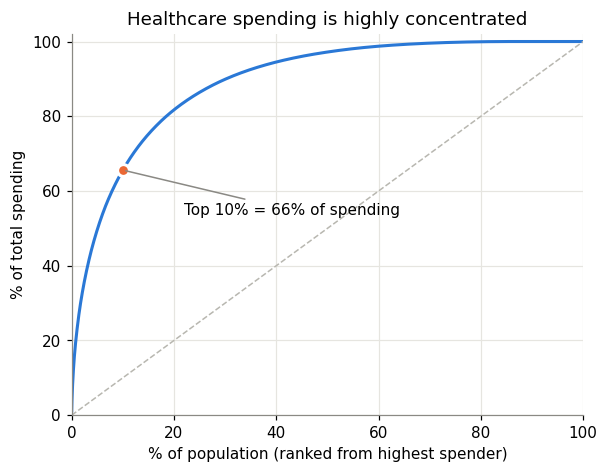

In [8]:
order = np.argsort(-y.values)
ys, ws = y.values[order], w.values[order]
pop_share = np.cumsum(ws) / ws.sum()
spend_share = np.cumsum(ys * ws) / (ys * ws).sum()

for p in [0.01, 0.05, 0.10, 0.20, 0.50]:
    print(f"Top {p:>4.0%} of people account for {np.interp(p, pop_share, spend_share):5.1%} of spending")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(pop_share * 100, spend_share * 100, color=BLUE, lw=2)
ax.plot([0, 100], [0, 100], color=GRAY, lw=1, ls="--")
s10 = np.interp(0.10, pop_share, spend_share) * 100
ax.scatter([10], [s10], color=ORANGE, s=60, zorder=3, edgecolor="white", linewidth=2)
ax.annotate(f"Top 10% = {s10:.0f}% of spending", (10, s10), xytext=(22, s10 - 12),
            arrowprops=dict(arrowstyle="-", color="#8a8984"))
ax.set(xlabel="% of population (ranked from highest spender)", ylabel="% of total spending",
       title="Healthcare spending is highly concentrated", xlim=(0, 100), ylim=(0, 102))
plt.show()

### Define the target: `high_cost`

**High cost = annual total expenditure at or above the weighted 90th percentile.**

In [9]:
HIGH_COST_THRESHOLD = wquantile(y, w, 0.90)
df["high_cost"] = (df.total_exp >= HIGH_COST_THRESHOLD).astype(int)

print(f"High-cost threshold: ${HIGH_COST_THRESHOLD:,.0f}")
print(f"Sample: {df.high_cost.sum():,} high-cost people ({df.high_cost.mean():.1%} unweighted, "
      f"{np.average(df.high_cost, weights=df.weight):.1%} weighted)")

grp = df.groupby("high_cost").apply(lambda g: pd.Series({
    "people (M)": g.weight.sum() / 1e6,
    "mean spending ($)": wmean(g.total_exp, g.weight),
    "median spending ($)": wquantile(g.total_exp, g.weight, 0.5),
    "share of US spending (%)": (g.total_exp * g.weight).sum() / (df.total_exp * df.weight).sum() * 100,
}), include_groups=False)
grp.index = ["Not high cost", "High cost (top 10%)"]
grp

High-cost threshold: $19,928
Sample: 2,182 high-cost people (11.7% unweighted, 10.0% weighted)


,people (M),mean spending ($),median spending ($),share of US spending (%)
Not high cost,305.81,"3,190.39","1,293.00",34.40
High cost (top 10%),33.99,"54,743.28","36,555.56",65.60


### 3.2 Who is high cost? Comparing groups

For each factor we show the **weighted % of people who are high cost** (the dashed line is the overall 10%), plus a table with mean and median spending.

In [10]:
OVERALL_RATE = np.average(df.high_cost, weights=df.weight) * 100

def group_profile(col):
    d = df.dropna(subset=[col])
    out = d.groupby(col, observed=True).apply(lambda g: pd.Series({
        "n (sample)": len(g),
        "pop (M)": g.weight.sum() / 1e6,
        "% high cost": np.average(g.high_cost, weights=g.weight) * 100,
        "mean spending ($)": wmean(g.total_exp, g.weight),
        "median spending ($)": wquantile(g.total_exp, g.weight, 0.5),
    }), include_groups=False)
    out["rate vs overall (x)"] = out["% high cost"] / OVERALL_RATE
    return out

def plot_rate(col, title, ax):
    t = group_profile(col)
    ax.barh(t.index.astype(str), t["% high cost"], color=BLUE, height=0.6)
    ax.axvline(OVERALL_RATE, color="#52514e", ls="--", lw=1)
    for i, v in enumerate(t["% high cost"]):
        ax.text(v + 0.5, i, f"{v:.0f}%", va="center", fontsize=9, color="#0b0b0b")
    ax.invert_yaxis()
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("% high cost")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)

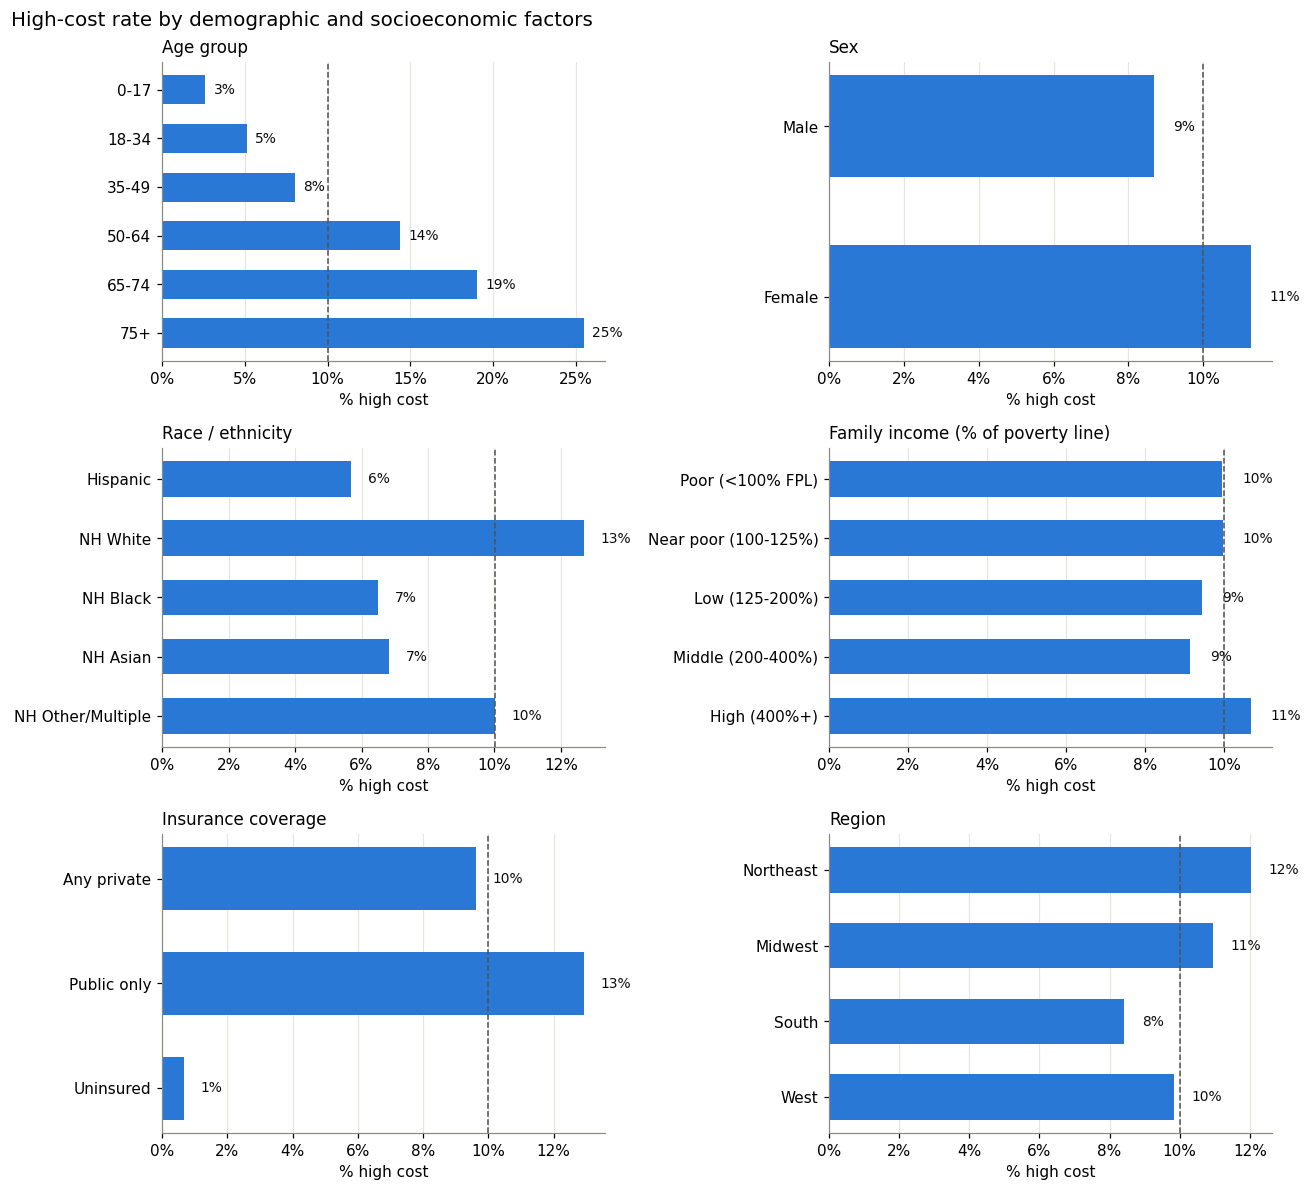

In [11]:
demo = [("age_group", "Age group"), ("sex_lbl", "Sex"), ("race_eth_lbl", "Race / ethnicity"),
        ("income_cat_lbl", "Family income (% of poverty line)"), ("insurance_lbl", "Insurance coverage"),
        ("region_lbl", "Region")]
fig, axes = plt.subplots(3, 2, figsize=(12, 11))
for (col, title), ax in zip(demo, axes.flat):
    plot_rate(col, title, ax)
fig.suptitle("High-cost rate by demographic and socioeconomic factors", fontsize=13, x=0.01, ha="left")
plt.tight_layout(); plt.show()

Age has by far the strongest effect, with the high-cost rate rising steadily from 3% for children to 25% for people 75 and older. Sex, race/ethnicity, income and region vary only modestly around the 10% average, and the uninsured rate is just 1%, which more likely shows limited access to care than low medical need.

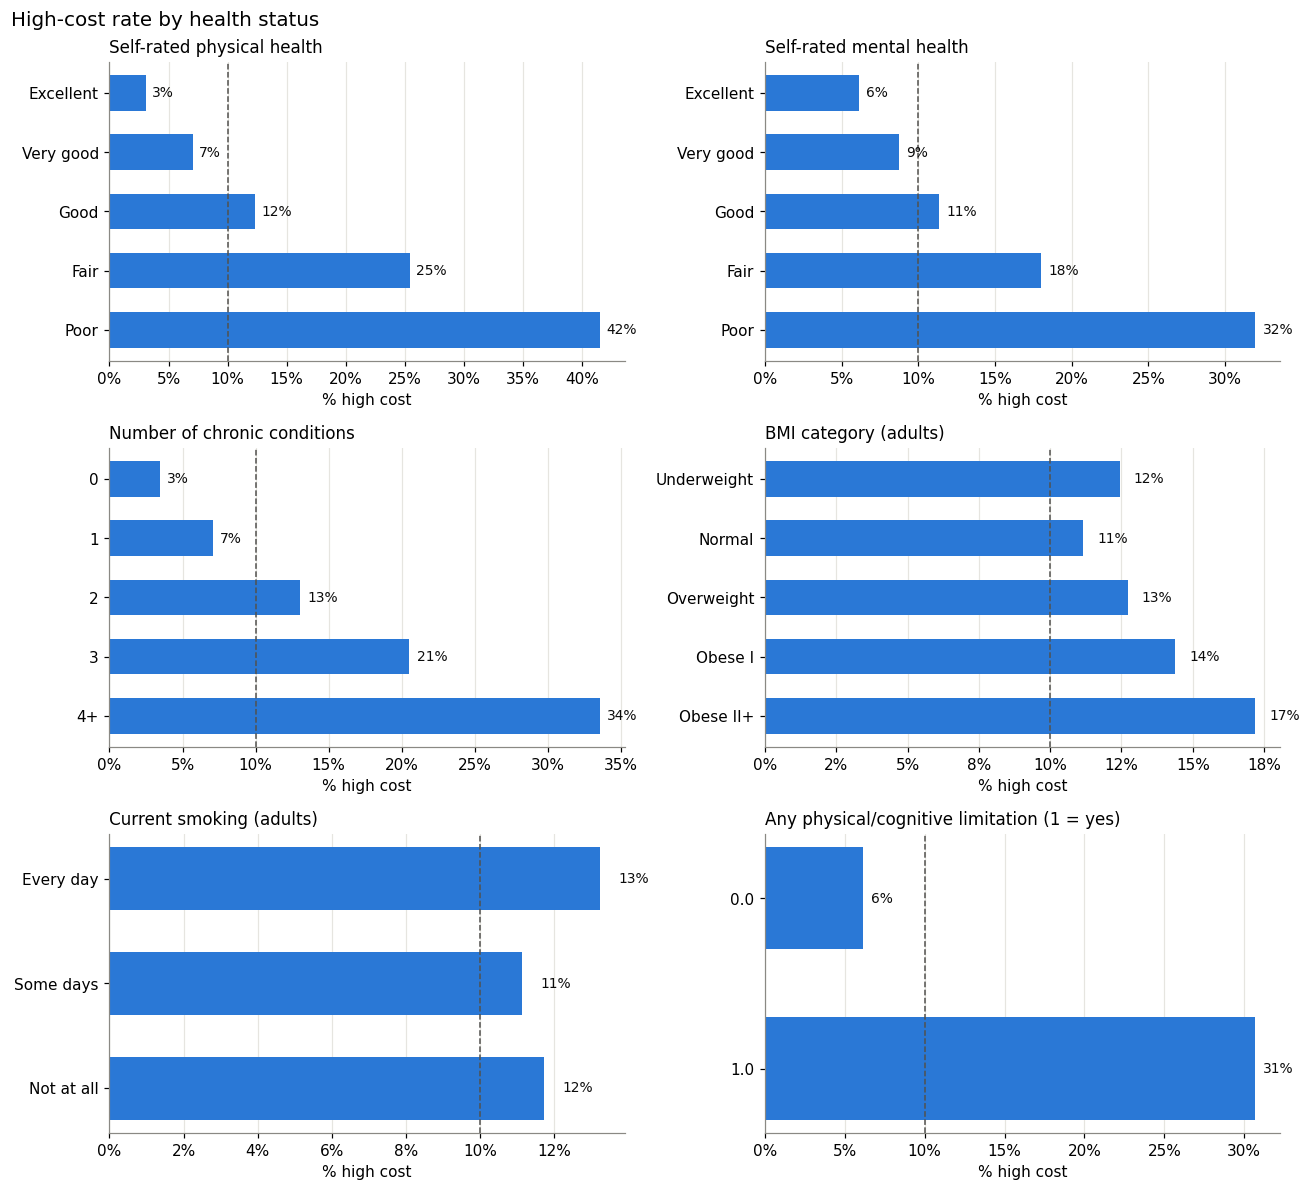

In [12]:
health = [("self_health_lbl", "Self-rated physical health"), ("mental_health_lbl", "Self-rated mental health"),
          ("n_conditions_grp", "Number of chronic conditions"), ("bmi_cat", "BMI category (adults)"),
          ("smoking_lbl", "Current smoking (adults)"), ("any_limitation", "Any physical/cognitive limitation (1 = yes)")]
fig, axes = plt.subplots(3, 2, figsize=(12, 11))
for (col, title), ax in zip(health, axes.flat):
    plot_rate(col, title, ax)
fig.suptitle("High-cost rate by health status", fontsize=13, x=0.01, ha="left")
plt.tight_layout(); plt.show()

Self-reported health is a strong signal: 42% of people in poor physical health and 31% of people with any physical or cognitive limitation are high cost, compared with 3% and 6% of those in excellent health or with no limitation. Each additional chronic condition raises the rate sharply (3% with none, 34% with four or more), while BMI and smoking change it only slightly.

### Individual chronic conditions

How much more likely is someone with each diagnosis to be high cost? (Adults only, since children were not asked.)

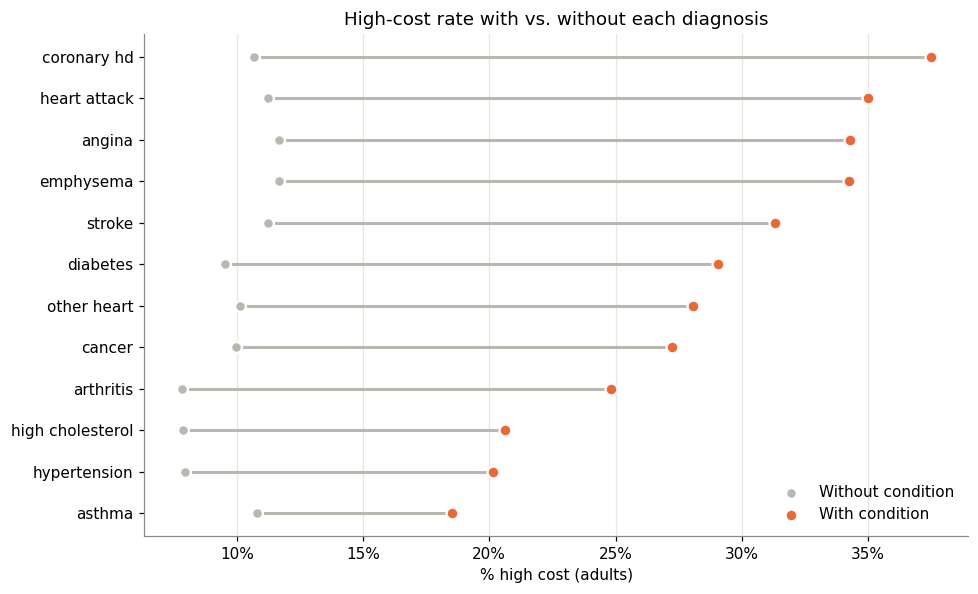

,% of adults with it,% high cost | has it,% high cost | doesn't,mean spending | has it ($),relative risk
condition,,,,,
coronary_hd,4.76,37.48,10.69,"25,429.31",3.51
heart_attack,3.13,34.99,11.22,"23,643.86",3.12
angina,1.29,34.31,11.68,"24,013.83",2.94
emphysema,1.33,34.26,11.66,"23,537.20",2.94
stroke,3.52,31.34,11.25,"23,327.38",2.79
diabetes,12.11,29.04,9.52,"19,570.29",3.05
other_heart,10.36,28.08,10.11,"20,676.48",2.78
cancer,11.58,27.23,9.97,"21,623.10",2.73
arthritis,24.31,24.82,7.81,"17,913.79",3.18


In [14]:
adults = df[df.age >= 18]
rows = []
for c in conditions:
    d = adults.dropna(subset=[c])
    yes, no = d[d[c] == 1], d[d[c] == 0]
    rows.append({
        "condition": c,
        "% of adults with it": np.average(d[c], weights=d.weight) * 100,
        "% high cost | has it": np.average(yes.high_cost, weights=yes.weight) * 100,
        "% high cost | doesn't": np.average(no.high_cost, weights=no.weight) * 100,
        "mean spending | has it ($)": wmean(yes.total_exp, yes.weight),
    })
cond = pd.DataFrame(rows).set_index("condition")
cond["relative risk"] = cond["% high cost | has it"] / cond["% high cost | doesn't"]
cond = cond.sort_values("% high cost | has it", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5.5))
ypos = np.arange(len(cond))
ax.hlines(ypos, cond["% high cost | doesn't"], cond["% high cost | has it"], color=GRAY, lw=2)
ax.scatter(cond["% high cost | doesn't"], ypos, color=GRAY, s=50, label="Without condition", zorder=3, edgecolor="white", linewidth=1.5)
ax.scatter(cond["% high cost | has it"], ypos, color=ORANGE, s=60, label="With condition", zorder=3, edgecolor="white", linewidth=1.5)
ax.set_yticks(ypos); ax.set_yticklabels(cond.index.str.replace("_", " "))
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set(xlabel="% high cost (adults)", title="High-cost rate with vs. without each diagnosis")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()
cond.round(2)

Among adults, cardiovascular and lung conditions carry the most risk: about 34–37% of adults with coronary heart disease, a past heart attack, angina or emphysema are high cost, compared with about 11% of those without. Common conditions such as hypertension, high cholesterol and asthma raise the rate less (18–21%), but because they are so widespread they still cover large numbers of members.



### Interaction: age × number of chronic conditions

Age and chronic conditions are strongly related (older people have more conditions). This heatmap separates the two: within each age group, does having more conditions still raise the high-cost rate?

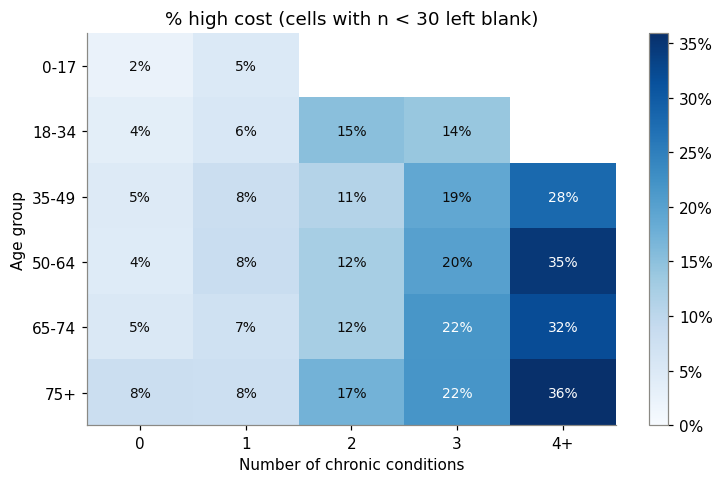

In [15]:
heat = (df.groupby(["age_group", "n_conditions_grp"], observed=True)
          .apply(lambda g: np.average(g.high_cost, weights=g.weight) * 100 if len(g) >= 30 else np.nan, include_groups=False)
          .unstack())
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if v > np.nanmax(heat.values) * 0.6 else "#0b0b0b")
ax.set(xlabel="Number of chronic conditions", ylabel="Age group", title="% high cost (cells with n < 30 left blank)")
ax.grid(False); plt.colorbar(im, ax=ax, format=mtick.PercentFormatter(decimals=0))
plt.tight_layout(); plt.show()

Within every age group, the high-cost rate rises steeply with the number of conditions, reaching 28–36% at four or more. Age has little effect once conditions are held constant (people with no conditions stay at 2–8% in every age group), so condition count, not age itself, appears to drive cost.



### 3.3. What do high-cost patients spend money on?

Useful for care management: if high-cost spending is driven by hospital stays, programs that prevent admissions matter most; if it's prescriptions, medication management matters.

Components sum to total_exp for 100.0% of people


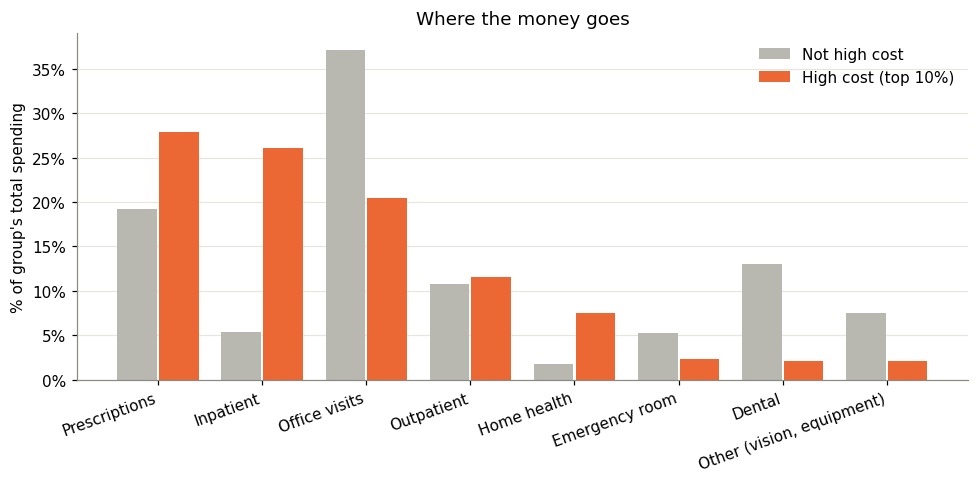

,Not high cost,High cost
Prescriptions,19.20,27.90
Inpatient,5.40,26.00
Office visits,37.10,20.40
Outpatient,10.70,11.50
Home health,1.70,7.50
Emergency room,5.30,2.40
Dental,13.10,2.10
"Other (vision, equipment)",7.50,2.10


In [16]:
comp_cols = {"exp_inpatient": "Inpatient", "exp_office": "Office visits", "exp_rx": "Prescriptions",
             "exp_outpatient": "Outpatient", "exp_er": "Emergency room", "exp_dental": "Dental",
             "exp_homehealth_agency": "Home health", "exp_homehealth_other": "Home health",
             "exp_vision": "Other (vision, equipment)", "exp_other": "Other (vision, equipment)"}
recon = df[list(comp_cols)].sum(axis=1)
print(f"Components sum to total_exp for {np.isclose(recon, df.total_exp, atol=1).mean():.1%} of people")

comp = (df[list(comp_cols)].mul(df.weight, axis=0)
          .groupby(df.high_cost).sum()
          .T.groupby(lambda c: comp_cols[c]).sum())
comp.columns = ["Not high cost", "High cost"]
share = comp.div(comp.sum()) * 100
share = share.sort_values("High cost", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(share)); bw = 0.38
ax.bar(x - bw/2 - 0.01, share["Not high cost"], bw, color=GRAY, label="Not high cost")
ax.bar(x + bw/2 + 0.01, share["High cost"], bw, color=ORANGE, label="High cost (top 10%)")
ax.set_xticks(x); ax.set_xticklabels(share.index, rotation=20, ha="right")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set(ylabel="% of group's total spending", title="Where the money goes")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
share.round(1)

In [17]:
# Utilization: high-cost vs others (weighted means)
util = ["n_office_visits", "n_er_visits", "n_inpatient_stays", "n_rx_fills"]
df.groupby("high_cost").apply(lambda g: pd.Series({u: wmean(g[u], g.weight) for u in util}), include_groups=False) \
  .rename(index={0: "Not high cost", 1: "High cost"}).round(2)

,n_office_visits,n_er_visits,n_inpatient_stays,n_rx_fills
high_cost,,,,
Not high cost,5.19,0.14,0.03,6.41
High cost,24.18,0.78,0.61,31.46


For high-cost patients, inpatient stays (26%) and prescriptions (28%) make up over half of spending, while for everyone else office visits (37%) and dental care (13%) dominate. This points care-management efforts toward preventing hospital admissions and managing medications, with home health (7.5%) as a smaller but notable third area.



### 3.4 Correlations among candidate predictors

Checking for redundancy before modeling (e.g., age vs. number of conditions vs. self-rated health). Spearman is used because spending is heavily skewed.

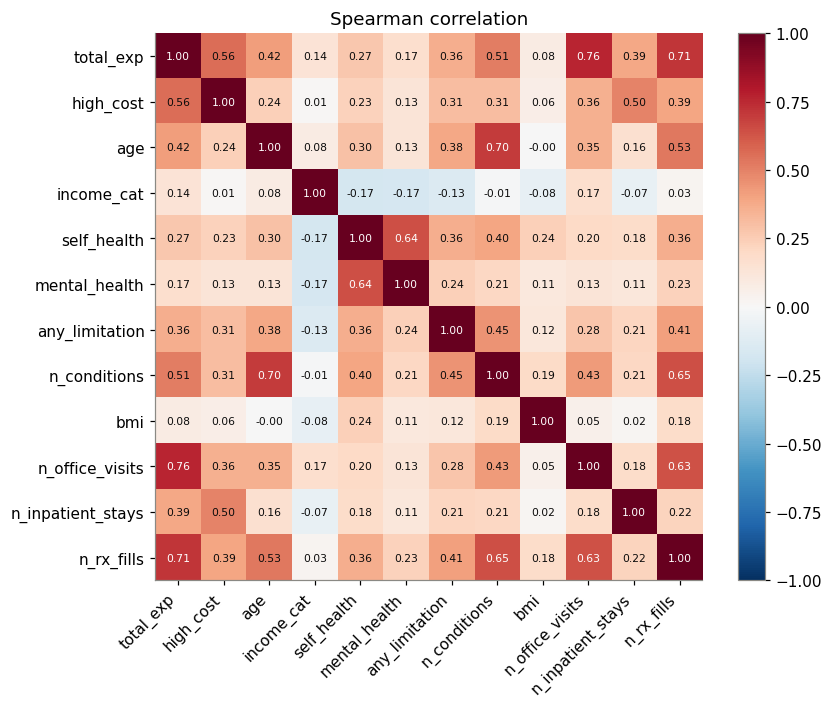

In [18]:
num = ["total_exp", "high_cost", "age", "income_cat", "self_health", "mental_health", "any_limitation",
       "n_conditions", "bmi", "n_office_visits", "n_inpatient_stays", "n_rx_fills"]
corr = df[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=45, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "#0b0b0b")
ax.grid(False); plt.colorbar(im, ax=ax); ax.set_title("Spearman correlation")
plt.tight_layout(); plt.show()

Number of chronic conditions (ρ = 0.51), age (0.42) and limitation status (0.36) are the predictors most correlated with total spending, while income and BMI are close to zero. Some predictors overlap heavily, such as age with conditions (0.70) and physical with mental self-rated health (0.64), so the model should check for multicollinearity; utilization counts are excluded from the model because they are essentially part of spending itself.



